# RecSys, ДЗ 1
Владислав Мухаметов

Рекомендую пользователю 10 товаров, которые он ещё не оценивал. Положительный отклик — отзыв на 4 или 5 звёзд.

Данные: [Amazon Review Data 2018, Musical Instruments, 5-core](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html).
`reviewerID` — пользователь, `asin` — товар, `overall` — оценка, `unixReviewTime` — время отзыва.
Из карточек товаров беру бренд и название. Тексты отзывов не использую.

Запуск: Python 3.12, `pip install -r requirements.txt`, открыть ноутбук в Jupyter и **Run → Run All Cells**.
Данные скачаются в `data/`. Для EASE желательно 16 ГБ RAM.
Формулы методов разобраны в [лекциях и семинарах курса](https://github.com/girafe-ai/recsys/tree/26f), темы CF, ALS, EASE и FM.

In [1]:
import gc
import itertools
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from experiment import (download_data, load_data, split_data, interaction_matrix,
                        item_features, evaluation_users, evaluate)
from models.item_knn import ItemKNN
from models.ials import ImplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_ials import CustomIALS

SEED = 42
K = 10
PRIMARY_METRIC = 'NDCG@10'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
pd.set_option('display.max_colwidth', 150)
pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## Данные

Беру всю категорию. Удаляю строки с пропущенными ключами и неверными оценками, затем повторы user–item.
Для повторов оставляю первый отзыв по времени: задача — рекомендовать новый товар, а не повторное взаимодействие.
При совпадении времени сохраняется порядок строк. В метаданных также оставляю первую запись ASIN.

In [2]:
DATA_DIR = Path('data')
download_data(DATA_DIR)
raw, data, metadata, stats = load_data(DATA_DIR)
display(pd.Series(stats, name='count').to_frame())
display(raw.isna().sum().rename('missing').to_frame())
assert 100_000 <= len(data) <= 2_000_000
assert data.user_id.nunique() >= 1000 and data.item_id.nunique() >= 1000
assert not data.duplicated(['user_id', 'item_id']).any()
print('Period:', pd.to_datetime(data.timestamp.min(), unit='s'), '—',
      pd.to_datetime(data.timestamp.max(), unit='s'))
print('Sparsity:', 1 - len(data) / (data.user_id.nunique() * data.item_id.nunique()))
display(data.head().drop(columns='user_id'))

,count
raw_rows,231392
invalid_rows,0
repeated_pairs,12236
clean_rows,219156
users,27530
items,10620
metadata_rows,120310
metadata_duplicate_ids,8175
metadata_nonempty_categories,114397


,missing
user_id,0
item_id,0
rating,0
timestamp,0


Period: 2003-10-28 00:00:00 — 2018-09-28 00:00:00
Sparsity: 0.9992504119799459


,item_id,rating,timestamp
0,B00006HO3L,4.0,1067299200
1,B00001W0DH,3.0,1080345600
2,B00001W0DT,4.0,1086048000
3,B00006HOLL,5.0,1086048000
4,B0002CZVKA,4.0,1090281600


## EDA

Посмотрю на оценки, активность пользователей, популярность товаров и заполненность метаданных.
Дополнительно редкие ID не отбрасываю.

,events_per_user,events_per_item
count,27530.000000,10620.000000
mean,7.960625,20.636158
std,5.890834,58.183222
min,1.000000,1.000000
25%,5.000000,6.000000
50%,6.000000,9.000000
75%,9.000000,18.000000
max,229.000000,1756.000000


,missing_count,missing_fraction
title,9,0.000847
brand,95,0.008945


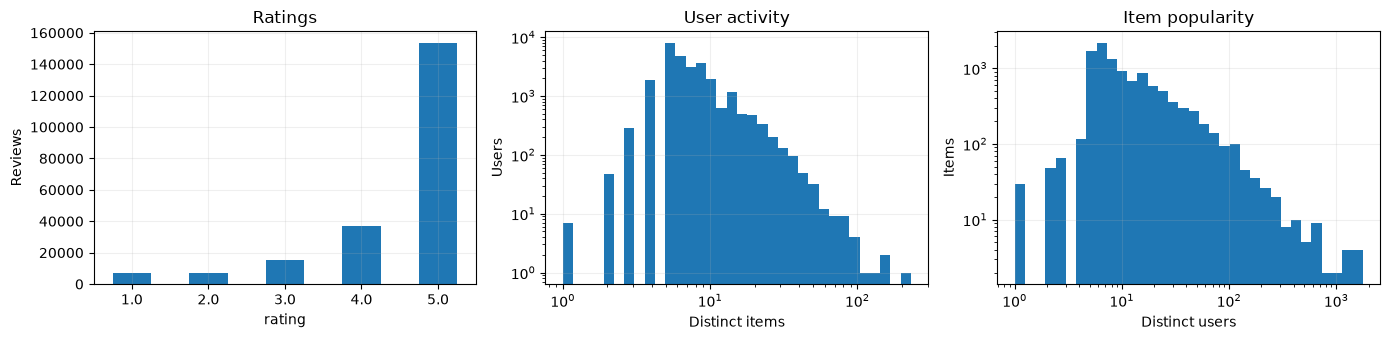

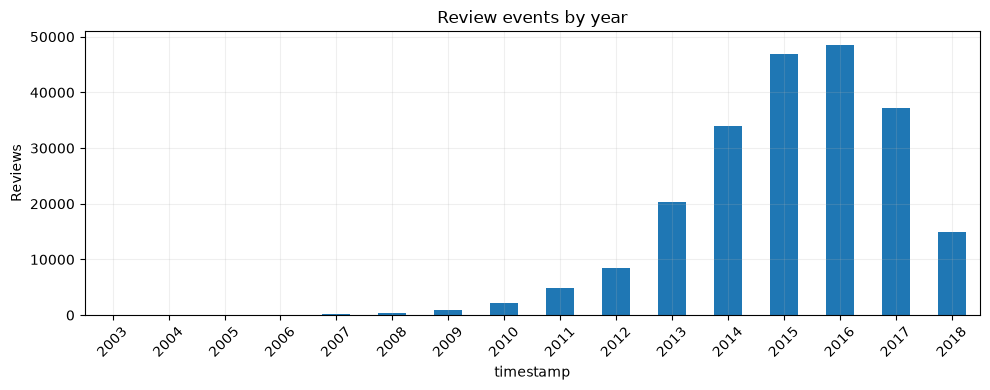

,items
brand,
Fender,421
JIM DUNLOP,252
Behringer,226
Yamaha,176
OnStage,148
Kmise,128
D'Addario Accessories,122
D'Addario,116
Shure,113


In [3]:
activity = data.groupby('user_id').size()
popularity = data.groupby('item_id').size()
display(pd.DataFrame({'events_per_user': activity.describe(), 'events_per_item': popularity.describe()}))
catalog = metadata.reindex(sorted(data.item_id.unique())).fillna('')
display(pd.DataFrame({'missing_count': (catalog == '').sum(),
                      'missing_fraction': (catalog == '').mean()}))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
data.rating.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title='Ratings')
axes[0].set_ylabel('Reviews')
axes[1].hist(activity, bins=np.geomspace(1, activity.max() + 1, 35))
axes[1].set(xscale='log', yscale='log', title='User activity', xlabel='Distinct items', ylabel='Users')
axes[2].hist(popularity, bins=np.geomspace(1, popularity.max() + 1, 35))
axes[2].set(xscale='log', yscale='log', title='Item popularity', xlabel='Distinct users', ylabel='Items')
fig.tight_layout(); plt.show()
annual = data.groupby(pd.to_datetime(data.timestamp, unit='s').dt.year).size()
annual.plot.bar(title='Review events by year', ylabel='Reviews', rot=45)
plt.tight_layout(); plt.show()
display(catalog.brand.value_counts().head(12).rename('items').to_frame())

## Разбиение и метрики

Разбиваю по времени примерно на 80/10/10: train до 27.02.2017 включительно,
validation до 01.10.2017, остальное test. Границы — процентили timestamp; один день не попадает в разные части.
Каталог и пользователи фиксируются по train. Новые ID исключаю, их количество видно в таблице ниже.

Оцениваю пользователей хотя бы с одним положительным событием и десятью доступными кандидатами.
Кандидаты — весь train-каталог. Убираю все ранее оценённые товары, включая оценки 1–3.
При равных score порядок задаётся ASIN. Эти правила одинаковы для всех моделей.

Главная метрика — **NDCG@10**: $DCG=\sum_{j=1}^{10}rel_j/\log_2(j+1)$, $NDCG=DCG/IDCG$.
Она учитывает позицию найденного товара. **Recall@10** — доля будущих положительных товаров,
попавших в top-10. Усредняю по пользователям. Дополнительно считаю долю каталога в рекомендациях.

Настройки выбираю по validation NDCG. Для финальной оценки переобучаюсь на train+validation,
исключая уже эту историю из кандидатов; словарь признаков остаётся прежним.

In [4]:
(train, validation, test), SHAPE, item_ids, cutoffs, split_stats = split_data(data)
display(split_stats)
print('Cutoffs UTC:', pd.to_datetime(list(cutoffs), unit='s').tolist())
print('Frozen train universe:', SHAPE)
train_positive = interaction_matrix(train, SHAPE, positive_only=True)
train_seen = interaction_matrix(train, SHAPE)
val_users, val_truth = evaluation_users(validation, train_seen, SHAPE)
print('Validation users:', len(val_users), '| relevant pairs:', val_truth.nnz)
print('Validation users without positive train history:',
      int((train_positive[val_users].getnnz(axis=1) == 0).sum()))
assert train.timestamp.max() < validation.timestamp.min() < test.timestamp.min()
assert not train_seen.multiply(val_truth).nnz

,split,all_events,cold_user_events,cold_item_events,warm_events,warm_positive_events
0,train,175360,0,0,175360,152355
1,validation,21904,6399,234,15316,13184
2,test,21892,7819,515,13721,11527


Cutoffs UTC: [Timestamp('2017-02-27 00:00:00'), Timestamp('2017-10-01 00:00:00')]
Frozen train universe: (25436, 10521)
Validation users: 5646 | relevant pairs: 13184
Validation users without positive train history: 134


## Модели

**ItemKNN.** Для бинарной положительной истории $X$ считаю $n=X^TX$ и cosine similarity
$s_{ij}=n_{ij}/\sqrt{n_{ii}n_{jj}}\cdot n_{ij}/(n_{ij}+\gamma)$.
Оставляю k соседей каждого товара, обнуляю диагональ. Рекомендации получаются из $XS$.

**iALS.** Минимизирую
$\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2)$,
где $p=1[r\ge4]$, $c=1+\alpha p$.
Поочерёдно обновляю факторы пользователей и товаров, решая
$(Y^TC_uY+\lambda I)x_u=Y^TC_up_u$ через Cholesky.
На положительных парах $c=1+\alpha$, поэтому в правой части стоит $(1+\alpha)\sum_i p_{ui}y_i$.

**EASE.** Минимизирую $\|X-XB\|_F^2+\lambda\|B\|_F^2$ при $diag(B)=0$.
Если $P=(X^TX+\lambda I)^{-1}$, то $B_{ij}=-P_{ij}/P_{jj}$, а диагональ равна нулю.
Деление идёт по столбцам. Матрица плотная, поэтому память растёт квадратично по числу товаров.

**FM.** $s(z)=\sum_a w_az_a+\frac12\sum_f[(\sum_a v_{af}z_a)^2-\sum_a v_{af}^2z_a^2]$.
Признаки: ID пользователя и товара, бренд one-hot, слова названия. Словарь — до 512 слов
с частотой от 5 товаров в train, до 8 слов на товар; текстовый блок нормирую.
Пропущенный бренд — отдельное значение. Название и бренд считаю свойствами карточки,
доступными при рекомендации. Цены, рейтинги карточек и helpfulness не использую.

Обучаю FM с BPR: $softplus(s(u,j)-s(u,i))$ плюс L2 участвующих эмбеддингов.
Adam, полный проход по положительным парам за эпоху; негативы равномерные из неизвестных
пользователю товаров. Отдельно обучаю FM только с ID для сравнения метаданных.

**Custom iALS.** Confidence сохраняю, меняю только таргет:
$$p^*_{ui}=\frac{r_{ui}-3}{2}\left(\frac12+\frac12\,2^{-(T-t_{ui})/(86400h)}\right),\quad r_{ui}\ge4.$$
На остальных парах таргет нулевой. Пять звёзд означают более сильный интерес, свежие отзывы весят больше старых.
При $h=\infty$ остаётся только сила оценки. Базовые настройки беру у лучшего iALS,
чтобы сравнивать именно таргеты, и отдельно подбираю h.

In [5]:
side_ids, side_values, feature_stats = item_features(metadata, item_ids, SHAPE[0])
plain_ids, plain_values, _ = item_features(metadata, item_ids, SHAPE[0], with_metadata=False)
display(pd.Series(feature_stats, name='train catalog').to_frame())
print('Feature width:', side_ids.shape[1], '| total feature indices:', int(side_ids.max()) + 1)

def fit_model(name, params, positive, seen, events, cutoff):
    if name == 'ItemKNN':
        return ItemKNN(**params).fit(positive)
    if name == 'iALS':
        return ImplicitALS(**params, seed=SEED).fit(positive)
    if name == 'EASE':
        return EASE(**params).fit(positive)
    if name == 'Custom iALS':
        return CustomIALS(**params, seed=SEED).fit(positive, events, cutoff)
    if name in ['FM + metadata', 'FM IDs']:
        ids, values = ((side_ids, side_values) if name == 'FM + metadata'
                       else (plain_ids, plain_values))
        return FactorizationMachine(**params, seed=SEED).fit(positive, seen, ids, values)
    raise ValueError(name)

grids = {
    'ItemKNN': [dict(neighbors=k, shrinkage=s)
                for k, s in itertools.product([50, 200, 500, 1000], [0, 10, 50, 200])],
    'iALS': [dict(factors=f, alpha=a, reg=r, iterations=15)
             for f, a, r in itertools.product([32, 64, 128], [10, 40, 100], [1, 10, 100])],
    'EASE': [dict(reg=r) for r in [100, 300, 1000, 3000]],
    'FM + metadata': [dict(factors=f, epochs=e, learning_rate=0.01, reg=0.001)
                      for f, e in itertools.product([16, 32, 64], [8, 16, 32])],
    'FM IDs': [dict(factors=f, epochs=e, learning_rate=0.01, reg=0.001)
               for f, e in itertools.product([16, 32, 64], [8, 16, 32])],
}
display(pd.DataFrame([{'model': name, 'trials': len(grid), 'parameters': grid}
                      for name, grid in grids.items()]))

,train catalog
brands,1690
title_words,512
missing_brand,94
missing_title,9


Feature width: 10 | total feature indices: 38161


,model,trials,parameters
0,ItemKNN,16,"[{'neighbors': 50, 'shrinkage': 0}, {'neighbors': 50, 'shrinkage': 10}, {'neighbors': 50, 'shrinkage': 50}, {'neighbors': 50, 'shrinkage': 200}, {..."
1,iALS,27,"[{'factors': 32, 'alpha': 10, 'reg': 1, 'iterations': 15}, {'factors': 32, 'alpha': 10, 'reg': 10, 'iterations': 15}, {'factors': 32, 'alpha': 10,..."
2,EASE,4,"[{'reg': 100}, {'reg': 300}, {'reg': 1000}, {'reg': 3000}]"
3,FM + metadata,9,"[{'factors': 16, 'epochs': 8, 'learning_rate': 0.01, 'reg': 0.001}, {'factors': 16, 'epochs': 16, 'learning_rate': 0.01, 'reg': 0.001}, {'factors'..."
4,FM IDs,9,"[{'factors': 16, 'epochs': 8, 'learning_rate': 0.01, 'reg': 0.001}, {'factors': 16, 'epochs': 16, 'learning_rate': 0.01, 'reg': 0.001}, {'factors'..."


## Подбор параметров

Выбираю настройки по максимальному NDCG@10 на validation, при равенстве — первый вариант сетки.
Для custom iALS беру настройки лучшего iALS и проверяю h = 180, 365, 730 дней и вариант без затухания.
FM с метаданными и без них сравниваю на одной сетке.

In [6]:
validation_rows, selected = [], {}

def tune(name, candidates):
    best_score = -np.inf
    for params in candidates:
        started = time.perf_counter()
        model = fit_model(name, params, train_positive, train_seen, train, cutoffs[0])
        fit_seconds = time.perf_counter() - started
        metrics, _ = evaluate(model, val_users, train_seen, val_truth)
        validation_rows.append({'model': name, 'parameters': params.copy(),
                                **metrics, 'fit_seconds': fit_seconds})
        print(name, params, '| NDCG:', round(metrics[PRIMARY_METRIC], 5),
              '| seconds:', round(fit_seconds, 1), flush=True)
        if metrics[PRIMARY_METRIC] > best_score:
            best_score = metrics[PRIMARY_METRIC]
            selected[name] = params.copy()
        del model
        gc.collect()

for name, grid in grids.items():
    tune(name, grid)
custom_grid = [dict(**selected['iALS'], half_life_days=h) for h in [180, 365, 730, None]]
tune('Custom iALS', custom_grid)
validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values(['model', PRIMARY_METRIC], ascending=[True, False]))
display(pd.DataFrame([{'model': name, 'selected_parameters': params}
                      for name, params in selected.items()]))

ItemKNN {'neighbors': 50, 'shrinkage': 0} | NDCG: 0.00854 | seconds: 0.1
ItemKNN {'neighbors': 50, 'shrinkage': 10} | NDCG: 0.01909 | seconds: 0.1
ItemKNN {'neighbors': 50, 'shrinkage': 50} | NDCG: 0.02013 | seconds: 0.1
ItemKNN {'neighbors': 50, 'shrinkage': 200} | NDCG: 0.02042 | seconds: 0.1
ItemKNN {'neighbors': 200, 'shrinkage': 0} | NDCG: 0.00924 | seconds: 0.1
ItemKNN {'neighbors': 200, 'shrinkage': 10} | NDCG: 0.01941 | seconds: 0.1
ItemKNN {'neighbors': 200, 'shrinkage': 50} | NDCG: 0.02042 | seconds: 0.1
ItemKNN {'neighbors': 200, 'shrinkage': 200} | NDCG: 0.02064 | seconds: 0.1
ItemKNN {'neighbors': 500, 'shrinkage': 0} | NDCG: 0.00975 | seconds: 0.1
ItemKNN {'neighbors': 500, 'shrinkage': 10} | NDCG: 0.01947 | seconds: 0.1
ItemKNN {'neighbors': 500, 'shrinkage': 50} | NDCG: 0.02036 | seconds: 0.1
ItemKNN {'neighbors': 500, 'shrinkage': 200} | NDCG: 0.0207 | seconds: 0.1
ItemKNN {'neighbors': 1000, 'shrinkage': 0} | NDCG: 0.00998 | seconds: 0.0
ItemKNN {'neighbors': 1000, 's

,model,parameters,NDCG@10,Recall@10,Coverage@10,users,fit_seconds
66,Custom iALS,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15, 'half_life_days': 365}",0.022602,0.036768,0.087254,5646,12.784801
67,Custom iALS,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15, 'half_life_days': 730}",0.022322,0.036158,0.092006,5646,12.885102
65,Custom iALS,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15, 'half_life_days': 180}",0.022190,0.036454,0.080506,5646,12.870920
68,Custom iALS,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15, 'half_life_days': None}",0.021592,0.034788,0.099610,5646,12.931108
46,EASE,{'reg': 3000},0.022667,0.034917,0.481133,5646,7.344553
45,EASE,{'reg': 1000},0.019831,0.032423,0.487406,5646,7.108827
44,EASE,{'reg': 300},0.019248,0.032441,0.486361,5646,7.095004
43,EASE,{'reg': 100},0.018008,0.029601,0.493584,5646,7.895758
51,FM + metadata,"{'factors': 32, 'epochs': 16, 'learning_rate': 0.01, 'reg': 0.001}",0.017940,0.027131,0.159110,5646,5.713482
48,FM + metadata,"{'factors': 16, 'epochs': 16, 'learning_rate': 0.01, 'reg': 0.001}",0.017893,0.026540,0.107214,5646,4.035524


,model,selected_parameters
0,ItemKNN,"{'neighbors': 500, 'shrinkage': 200}"
1,iALS,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15}"
2,EASE,{'reg': 3000}
3,FM + metadata,"{'factors': 32, 'epochs': 16, 'learning_rate': 0.01, 'reg': 0.001}"
4,FM IDs,"{'factors': 64, 'epochs': 32, 'learning_rate': 0.01, 'reg': 0.001}"
5,Custom iALS,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15, 'half_life_days': 365}"


model,FM + metadata,FM IDs,metadata delta
setting,,,
"rank=16, epochs=16",0.017893,0.011110,0.006784
"rank=16, epochs=32",0.017776,0.010497,0.007279
"rank=16, epochs=8",0.017467,0.011514,0.005953
"rank=32, epochs=16",0.017940,0.012732,0.005209
"rank=32, epochs=32",0.015559,0.013010,0.002548
"rank=32, epochs=8",0.016380,0.012747,0.003632
"rank=64, epochs=16",0.016153,0.012179,0.003974
"rank=64, epochs=32",0.013800,0.013248,0.000552
"rank=64, epochs=8",0.016812,0.011125,0.005687


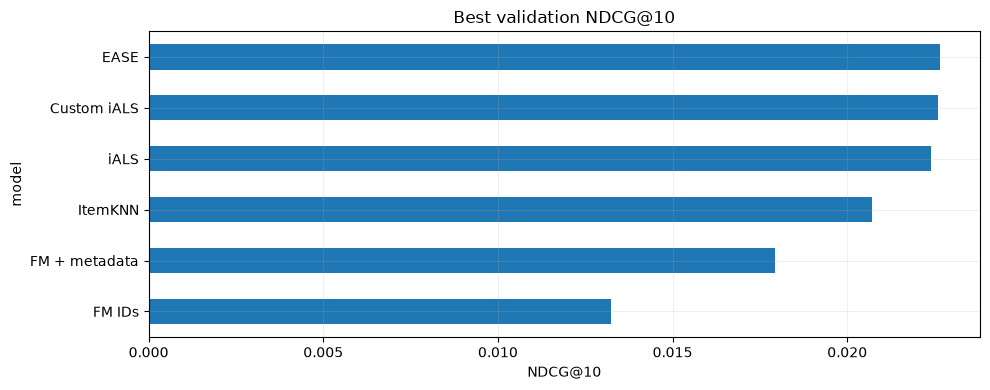

In [7]:
fm_validation = validation_results[validation_results.model.str.startswith('FM')].copy()
fm_validation['setting'] = fm_validation.parameters.map(lambda p: f"rank={p['factors']}, epochs={p['epochs']}")
paired_validation = fm_validation.pivot(index='setting', columns='model', values=PRIMARY_METRIC)
paired_validation['metadata delta'] = paired_validation['FM + metadata'] - paired_validation['FM IDs']
display(paired_validation)
ax = validation_results.groupby('model')[PRIMARY_METRIC].max().sort_values().plot.barh(
    title='Best validation NDCG@10', xlabel='NDCG@10')
plt.tight_layout(); plt.show()

## Test

Переобучаю выбранные модели на train+validation. Добавляю Popularity — число положительных событий
у товара — и FM только с ID. Для всех строк одна история, пользователи и кандидаты.

In [8]:
final_train = pd.concat([train, validation], ignore_index=True)
final_positive = interaction_matrix(final_train, SHAPE, positive_only=True)
final_seen = interaction_matrix(final_train, SHAPE)
test_users, test_truth = evaluation_users(test, final_seen, SHAPE)
assert not final_seen.multiply(test_truth).nnz
assert final_train.timestamp.max() < test.timestamp.min()
print('Test users:', len(test_users), '| relevant pairs:', test_truth.nnz)
print('Test users without positive fitting history:',
      int((final_positive[test_users].getnnz(axis=1) == 0).sum()))

test_rows, test_detail, fm_losses = [], {}, {}
for name, params in selected.items():
    started = time.perf_counter()
    model = fit_model(name, params, final_positive, final_seen, final_train, cutoffs[1])
    fit_seconds = time.perf_counter() - started
    metrics, detail = evaluate(model, test_users, final_seen, test_truth)
    test_rows.append({'model': name, **metrics, 'fit_seconds': fit_seconds,
                      'parameters': params.copy()})
    test_detail[name] = detail
    if hasattr(model, 'losses'):
        fm_losses[name] = model.losses
    print(name, '| NDCG:', round(metrics[PRIMARY_METRIC], 5),
          '| Recall:', round(metrics['Recall@10'], 5), flush=True)
    del model
    gc.collect()

class Popularity:
    def __init__(self, positive):
        self.values = np.asarray(positive.sum(axis=0)).ravel()
    def score(self, users):
        return np.tile(self.values, (len(users), 1))

metrics, detail = evaluate(Popularity(final_positive), test_users, final_seen, test_truth)
test_rows.append({'model': 'Popularity', **metrics, 'fit_seconds': 0.0, 'parameters': {}})
test_detail['Popularity'] = detail
test_results = pd.DataFrame(test_rows).sort_values(PRIMARY_METRIC, ascending=False).reset_index(drop=True)
display(test_results.round(5))
assert test_results.users.nunique() == 1
assert all(frame.user.equals(test_detail['iALS'].user) for frame in test_detail.values())

Test users: 5090 | relevant pairs: 11527
Test users without positive fitting history: 64
ItemKNN | NDCG: 0.01426 | Recall: 0.0216
iALS | NDCG: 0.01812 | Recall: 0.02762
EASE | NDCG: 0.0163 | Recall: 0.02597
FM + metadata | NDCG: 0.01184 | Recall: 0.0182
FM IDs | NDCG: 0.01116 | Recall: 0.01805
Custom iALS | NDCG: 0.01896 | Recall: 0.02955


,model,NDCG@10,Recall@10,Coverage@10,users,fit_seconds,parameters
0,Custom iALS,0.01896,0.02955,0.08402,5090,12.86694,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15, 'half_life_days': 365}"
1,iALS,0.01812,0.02762,0.10408,5090,12.73817,"{'factors': 64, 'alpha': 40, 'reg': 100, 'iterations': 15}"
2,Popularity,0.01759,0.02226,0.00200,5090,0.00000,{}
3,EASE,0.01630,0.02597,0.37420,5090,7.77743,{'reg': 3000}
4,ItemKNN,0.01426,0.02160,0.63549,5090,0.05763,"{'neighbors': 500, 'shrinkage': 200}"
5,FM + metadata,0.01184,0.01820,0.15274,5090,6.09173,"{'factors': 32, 'epochs': 16, 'learning_rate': 0.01, 'reg': 0.001}"
6,FM IDs,0.01116,0.01805,0.34084,5090,10.10083,"{'factors': 64, 'epochs': 32, 'learning_rate': 0.01, 'reg': 0.001}"


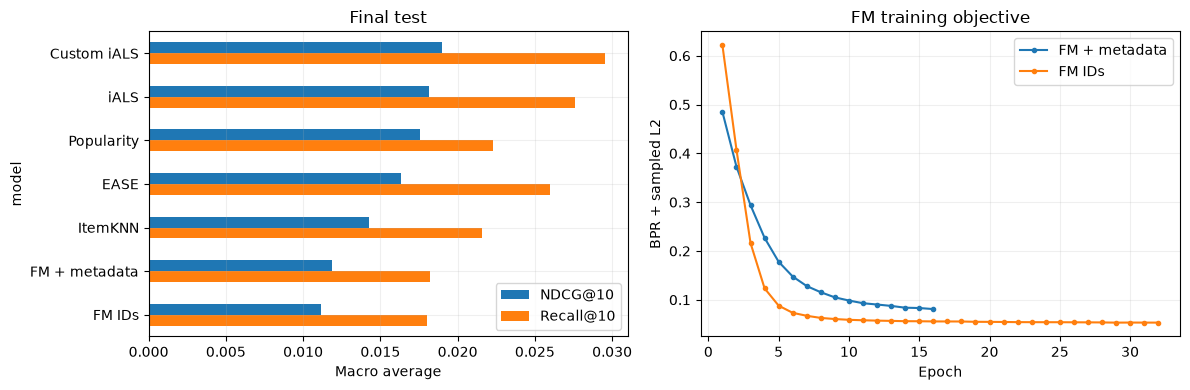

,comparison,mean_delta,lower_95,upper_95
0,Custom iALS − iALS,0.000843,-0.000538,0.002147
1,FM + metadata − FM IDs,0.000677,-0.001642,0.003098


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_results.set_index('model')[['NDCG@10', 'Recall@10']].plot.barh(ax=axes[0], title='Final test')
axes[0].set_xlabel('Macro average'); axes[0].invert_yaxis()
for name, losses in fm_losses.items():
    axes[1].plot(np.arange(1, len(losses) + 1), losses, marker='.', label=name)
axes[1].set(title='FM training objective', xlabel='Epoch', ylabel='BPR + sampled L2')
axes[1].legend()
fig.tight_layout(); plt.show()

def paired_bootstrap(first, second, repeats=2000):
    a = test_detail[first][PRIMARY_METRIC].to_numpy()
    b = test_detail[second][PRIMARY_METRIC].to_numpy()
    rng = np.random.default_rng(SEED)
    differences = a - b
    samples = np.array([rng.choice(differences, len(differences), replace=True).mean()
                        for _ in range(repeats)])
    return {'comparison': first + ' − ' + second, 'mean_delta': differences.mean(),
            'lower_95': np.quantile(samples, .025), 'upper_95': np.quantile(samples, .975)}

intervals = pd.DataFrame([paired_bootstrap('Custom iALS', 'iALS'),
                          paired_bootstrap('FM + metadata', 'FM IDs')])
display(intervals.round(6))

## Выводы

Лучший результат на test у custom iALS: **NDCG@10 = 0,01896**, **Recall@10 = 0,02955**.
У обычного iALS — 0,01812 и 0,02762, у Popularity — 0,01759 и 0,02226.
Оба варианта ALS обошли Popularity по NDCG: на 0,00053 и 0,00137 соответственно.

На validation выбраны 64 фактора, alpha=40, reg=100 и 15 итераций ALS.
Для custom лучше оказался h=365 дней. Его прирост к обычному iALS на test — 0,00084,
но 95% bootstrap-интервал [-0,00054; 0,00215] включает ноль. Рост есть в этой выборке,
убедительного подтверждения пользы таргета пока нет.

FM с брендом и названием получила NDCG 0,01184 против 0,01116 у FM только с ID
после отдельного подбора настроек. На validation метаданные помогли во всех девяти
сравнениях с одинаковыми параметрами. На test разница всего 0,00068, и её интервал
тоже включает ноль: [-0,00164; 0,00310].

EASE с reg=3000 дала NDCG 0,01630, KNN с 500 соседями и shrinkage=200 — 0,01426.
Они уступают Popularity по NDCG, зато охватывают заметно больше каталога:
37,4% и 63,5% против 0,2% у Popularity.

Ограничения:

- Это один временной срез; test уже использовался в предварительном эксперименте.
- Оцениваются только известные пользователи и товары, без новых ID.
- У метаданных нет исторических версий, а отсутствие отзыва не обязательно означает отсутствие интереса.